# 07 – So sánh tổng hợp các mô hình

So sánh 7 mô hình: Popularity(count), Content-based, ItemKNN, BiasedMF, ImplicitALS, NeuMF, BPR-MF. Gộp kết quả mà các notebook 04–07 đã lưu trong `outputs/metrics/` (bảng baseline do `python main.py evaluate --family baseline` tạo). **Mọi mô hình dùng chung một phép chia train/test và cùng tập đánh giá.**

- Top-N (K = 10): Precision, Recall, NDCG, HitRate (cao hơn tốt hơn). Phim liên quan = rating ≥ 4 trong tập test; ứng viên là mọi phim chưa xem trong train.
- Ngoài độ chính xác: Coverage (độ phủ catalog), Novelty (độ mới lạ), Diversity (đa dạng thể loại trong danh sách), tính trên Top-20.

In [1]:
import sys, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))          # để import được package src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})

from src.config import RESULTS_DIR
from src.experiment import load_experiment, make_validation, run_model, save_metrics

exp = load_experiment()                # cùng dữ liệu + cùng phép chia + cùng seed cho mọi notebook
FIG = RESULTS_DIR / "figures"; FIG.mkdir(parents=True, exist_ok=True)
print(f"train={len(exp.train):,}  test={len(exp.test):,}  users={len(exp.user2idx):,}  items={len(exp.item2idx):,}")

train=800,193  test=200,016  users=6,040  items=3,706


In [2]:
files = ["baseline", "content", "knn", "mf", "deep"]
res = pd.concat([pd.read_csv(RESULTS_DIR / "metrics" / f"{f}.csv") for f in files], ignore_index=True)
res.to_csv(RESULTS_DIR / "metrics" / "all_models.csv", index=False)
print(len(res), "mô hình"); res.Family.value_counts()

7 mô hình


Family
Matrix Factorization    2
Deep learning           2
Baseline                1
Content-based           1
Collaborative (kNN)     1
Name: count, dtype: int64

## Bảng kết quả – Xếp hạng Top-10 (sắp theo NDCG@10)

Trả lời câu hỏi: *trong 10 phim gợi ý, có bao nhiêu phim user thật sự thích, và chúng nằm ở vị trí nào?* Đây là nhóm chỉ số quan trọng nhất với một hệ thống gợi ý.

**Quy ước tính** (`src/evaluation/metrics.py`):
- Danh sách gợi ý của user = các phim điểm cao nhất, **đã loại phim user chấm trong train**.
- Phim **liên quan** = phim trong tập test được user chấm **≥ 4** (`RELEVANT_RATING`).
- Precision/Recall/NDCG/HitRate lấy trung bình trên các user có ít nhất 1 phim liên quan trong test.

*Ví dụ dùng chung bên dưới:* user có **5** phim liên quan; danh sách 10 phim trúng ở **vị trí 1 và 4**.

**Precision@10** – tỉ lệ phim gợi ý đúng gu

$$\text{Precision@}K = \frac{\#\text{phim trúng trong top-}K}{K}$$

Ví dụ: 2/10 = **0.2**. Precision@10 ≈ 0.24 nghĩa là trung bình khoảng 2–3 trong 10 phim gợi ý là phim user đã xem và thích.

**Recall@10** – tỉ lệ phim yêu thích mà mô hình tìm ra được

$$\text{Recall@}K = \frac{\#\text{phim trúng trong top-}K}{\#\text{phim liên quan của user}}$$

Ví dụ: 2/5 = **0.4**. User có nhiều phim liên quan (ví dụ 100) thì Recall@10 tối đa chỉ 10/100 = 0.1, nên giá trị trung bình thường thấp.

**NDCG@10** (Normalized Discounted Cumulative Gain) – độ chính xác *có tính thứ tự*

$$\text{DCG@}K = \sum_{p=1}^{K} \frac{\text{hit}_p}{\log_2(p+1)}, \qquad \text{NDCG@}K = \frac{\text{DCG@}K}{\text{IDCG@}K}$$

- Trúng ở vị trí càng cao càng được nhiều điểm (trọng số 1, 0.63, 0.5, 0.43, … , 0.29 cho vị trí 1 → 10).
- IDCG là DCG lý tưởng (mọi phim liên quan xếp đầu danh sách, tối đa K phim), nên NDCG ∈ [0, 1].
- Ví dụ: DCG = 1 + 1/log₂5 = 1.431; IDCG = 1 + 0.631 + 0.5 + 0.431 + 0.387 = 2.949; NDCG = **0.485**.
- Là **chỉ số chính để chọn mô hình gợi ý**, vì người dùng thường chỉ xem vài phim đầu danh sách.

**HitRate@10** – tỉ lệ user được gợi ý trúng ít nhất 1 phim

$$\text{HitRate@}K = \frac{\#\text{user có} \ge 1 \text{ phim trúng trong top-}K}{\#\text{user}}$$

Ví dụ: user trên có giá trị **1**. HitRate@10 ≈ 0.8 nghĩa là 80% user nhận được ít nhất một gợi ý đúng gu; đây là chỉ số dễ giải thích nhất với người không chuyên.

*Lưu ý khi đọc:* phim user chưa từng xem bị tính là "không liên quan" dù có thể user sẽ thích, và test chỉ chứa 20% lịch sử của mỗi user. Vì vậy giá trị tuyệt đối **đánh giá thấp** mọi mô hình như nhau; nên dùng các chỉ số này để **so sánh tương đối** giữa các mô hình.

**FitTime_s:** thời gian huấn luyện (giây, trên GPU). Không phản ánh chất lượng gợi ý, nhưng quan trọng khi ứng dụng phải huấn luyện lại (ví dụ có user mới).

In [3]:
cols = ["Model", "Family", "Precision@10", "Recall@10", "NDCG@10", "HitRate@10", "Coverage@20", "Novelty@20",
        "Diversity@20", "FitTime_s"]
t2 = res.sort_values("NDCG@10", ascending=False)[cols]
t2.round(4).reset_index(drop=True)

,Model,Family,Precision@10,Recall@10,NDCG@10,HitRate@10,Coverage@20,Novelty@20,Diversity@20,FitTime_s
0,NeuMF(f=128),Deep learning,0.2477,0.1693,0.2946,0.8135,0.4107,2.6258,0.6380,12.3079
1,BPR-MF(f=32),Deep learning,0.2293,0.1527,0.2711,0.7829,0.4903,2.6821,0.6355,7.4537
2,ImplicitALS(f=32),Matrix Factorization,0.2054,0.1690,0.2502,0.8220,0.5316,2.9809,0.6152,0.5827
3,Popularity(count),Baseline,0.1484,0.0862,0.1735,0.6064,0.0289,1.6693,0.7231,0.1133
4,ContentBased(genres+title),Content-based,0.0715,0.0441,0.0875,0.4269,0.0982,3.3239,0.5514,0.9769
5,"ItemKNN(k=5,pearson)",Collaborative (kNN),0.0581,0.0487,0.0668,0.4161,0.8486,3.9806,0.7130,0.7429
6,BiasedMF(f=200),Matrix Factorization,0.0541,0.0314,0.0582,0.3441,0.4757,4.7363,0.7247,10.2931


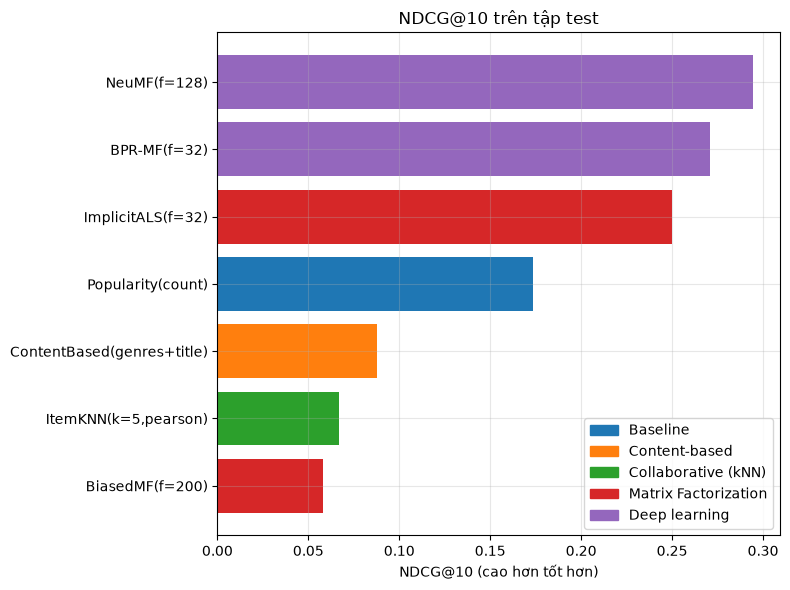

In [4]:
colors = dict(zip(res.Family.unique(), plt.cm.tab10.colors))
fig, ax = plt.subplots(figsize=(8, 6))
d = t2.iloc[::-1]; ax.barh(d.Model, d["NDCG@10"], color=[colors[f] for f in d.Family])
ax.set(title="NDCG@10 trên tập test", xlabel="NDCG@10 (cao hơn tốt hơn)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()], labels=list(colors), loc="lower right")
plt.tight_layout(); plt.savefig(FIG / "compare_ndcg.png"); plt.show()

## Ngoài độ chính xác: Coverage, Novelty, Diversity

Trả lời câu hỏi: *gợi ý có phong phú và đáng khám phá không, hay chỉ toàn phim bom tấn?* Tính trên danh sách **Top-20** của mọi user có trong test.

**Coverage@20** – độ phủ kho phim (cao hơn → dùng được nhiều phim hơn)

$$\text{Coverage@}K = \frac{\#\text{phim khác nhau xuất hiện trong danh sách của mọi user}}{\#\text{tổng số phim (3706)}}$$

- Popularity ≈ 0.03: mọi user nhận gần như cùng một danh sách (~100 phim). ItemKNN ≈ 0.84: gợi ý tới ~3.100 phim khác nhau.
- Coverage thấp nghĩa là phần lớn kho phim không bao giờ được gợi ý ("đuôi dài" bị bỏ quên).

**Novelty@20** – độ mới lạ (cao hơn → phim ít người biết hơn)

$$\text{Novelty@}K = \text{trung bình}\left[-\log_2 \text{pop}(i)\right], \qquad \text{pop}(i) = \frac{\#\text{user đã chấm phim } i \text{ (train)}}{\#\text{user}}$$

- Đổi ngược ra độ phổ biến trung bình: $\text{pop} \approx 2^{-\text{Novelty}}$. Novelty 2.4 → phim được ~19% user đã xem (phim nổi tiếng); Novelty 6.8 → ~0.9% (phim ít người biết).
- **Không phải cứ cao là tốt:** Novelty rất cao kèm NDCG gần 0 nghĩa là mô hình gợi ý phim lạ *mà user không thích*. Novelty chỉ có giá trị khi độ chính xác vẫn ổn.

**Diversity@20** – đa dạng thể loại *bên trong một danh sách* (cao hơn → trộn nhiều thể loại)

$$\text{Diversity@}K = 1 - \frac{1}{K(K-1)} \sum_{i \ne j \in \text{top-}K} \cos(\mathbf{g}_i, \mathbf{g}_j)$$

với $\mathbf{g}_i$ là vector multi-hot 18 thể loại của phim $i$; lấy trung bình trên các user.
- ContentBased ≈ 0.55: gợi ý theo thể loại nên danh sách toàn phim cùng loại. BiasedMF ≈ 0.72: danh sách trộn nhiều thể loại hơn.
- Khác Coverage: Coverage đo đa dạng **giữa các user** (toàn hệ thống), Diversity đo đa dạng **trong danh sách của một user**.

**Đọc kết hợp các chỉ số:**

| Tình huống | Ý nghĩa |
|---|---|
| NDCG cao, Novelty/Coverage thấp | Gợi ý trúng gu nhưng thiên về phim nổi tiếng – an toàn, ít bất ngờ |
| NDCG khá + Coverage cao | Cân bằng giữa trúng gu và khai thác đa dạng kho phim |
| Novelty rất cao, NDCG ≈ 0 | Gợi ý phim lạ nhưng vô dụng |

In [5]:
res.set_index("Model")[["Coverage@20", "Novelty@20", "Diversity@20"]].round(3).sort_values("Coverage@20", ascending=False)

,Coverage@20,Novelty@20,Diversity@20
Model,,,
"ItemKNN(k=5,pearson)",0.849,3.981,0.713
ImplicitALS(f=32),0.532,2.981,0.615
BPR-MF(f=32),0.490,2.682,0.635
BiasedMF(f=200),0.476,4.736,0.725
NeuMF(f=128),0.411,2.626,0.638
ContentBased(genres+title),0.098,3.324,0.551
Popularity(count),0.029,1.669,0.723


## Phân tích cold-start: phim ít rating trong train

**Recall@20 theo mức độ phổ biến của phim:** xét mọi cặp (user, phim liên quan) trong tập test, nhóm theo số rating của phim trong train, rồi tính tỉ lệ phim đó nằm trong top-20 gợi ý của user. Nhóm phim ít rating cho biết mô hình có gợi ý được phim "đuôi dài" mà user thích hay không.

Mô hình được nạp bằng `src.recommender.get_model` (dùng lại `models/<tên>.pkl` của ứng dụng nếu khớp dữ liệu và siêu tham số, nếu không thì huấn luyện lại trên train và lưu).

In [6]:
from src import recommender as rs
from src.config import RELEVANT_RATING
from src.evaluation.metrics import top_k_items

K = 20
cnt = exp.train.groupby("movie_id").size()
rel = exp.test[exp.test.rating >= RELEVANT_RATING]
bucket = pd.cut(rel.movie_id.map(cnt).fillna(0), [-1, 5, 20, 100, 1e9], labels=["<=5", "6-20", "21-100", ">100"])
users = np.sort(exp.test.user_id.unique())
uidx = np.array([exp.user2idx[u] for u in users])
row_of = pd.Series(np.arange(len(users)), index=users)
r, it = row_of[rel.user_id].to_numpy(), rel.movie_id.map(exp.item2idx).to_numpy()

def recall_by_bucket(m):
    top = top_k_items(m.score_matrix()[uidx], m.R[uidx], K)
    hit = (top[r] == it[:, None]).any(axis=1)
    return pd.Series(hit, index=rel.index).groupby(bucket, observed=True).mean()

cold = {}
for key in rs.MODELS:
    m = rs.get_model(key, exp, verbose=False)
    cold[m.name] = recall_by_bucket(m); del m
cold = pd.DataFrame(cold)
cold.insert(0, "n_rel_test", bucket.value_counts().reindex(cold.index)); cold.index.name = "Số rating của phim trong train"
cold.round(4)

,n_rel_test,Popularity(count),ContentBased(genres+title),"ItemKNN(k=5,pearson)",BiasedMF(f=200),ImplicitALS(f=32),NeuMF(f=128),BPR-MF(f=32)
Số rating của phim trong train,,,,,,,,
<=5,101,0.0000,0.0000,0.0198,0.0198,0.0000,0.0000,0.0000
6-20,572,0.0000,0.0000,0.0105,0.0105,0.0000,0.0000,0.0035
21-100,5713,0.0000,0.0040,0.0100,0.0161,0.0116,0.0067,0.0117
>100,108920,0.1357,0.0645,0.0590,0.0532,0.1929,0.2219,0.2079


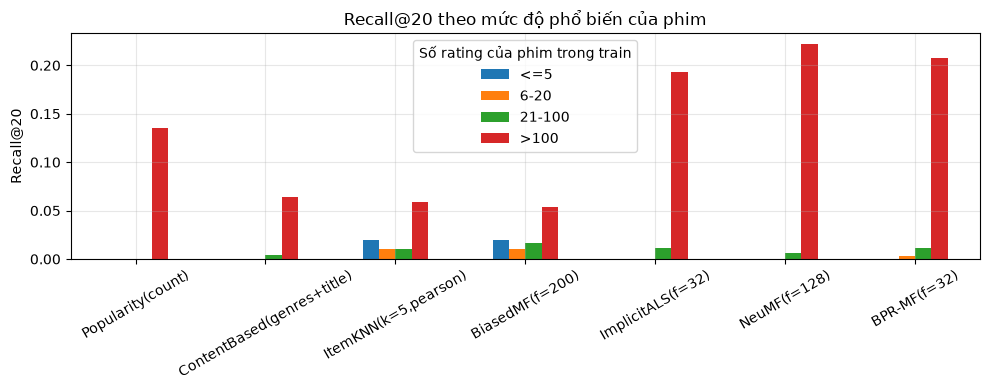

In [7]:
cold.drop(columns="n_rel_test").T.plot.bar(rot=30, figsize=(10, 4), ylabel=f"Recall@{K}",
                                            title=f"Recall@{K} theo mức độ phổ biến của phim")
plt.legend(title="Số rating của phim trong train"); plt.tight_layout()
plt.savefig(FIG / "cold_start_recall.png"); plt.show()

## Kết luận

*Bài toán: xếp hạng danh sách gợi ý Top-N, so sánh 7 mô hình. Số liệu từ lần huấn luyện trên GPU (RTX 4060, PyTorch CUDA); mọi mô hình trừ Popularity tính toán trên GPU. Siêu tham số được chọn trên tập validation theo **NDCG@10**.*

- **Xếp hạng Top-N:** NeuMF f=128 (NDCG@10 ≈ 0.295) > BPR-MF f=32 (≈ 0.271) > ImplicitALS f=32 (≈ 0.250) > Popularity(count) (≈ 0.174) > Content-based (≈ 0.088) > ItemKNN k=5 (≈ 0.067) > BiasedMF f=200 (≈ 0.058). Chỉ ba mô hình học từ phản hồi implicit vượt được mốc không cá nhân hóa Popularity(count). ImplicitALS có HitRate@10 cao nhất (≈ 0.822).
- **Nhất quán giữa validation và test:** thứ tự NeuMF > BPR-MF > ALS > ItemKNN > BiasedMF trên validation và trên test trùng nhau.
- **Hàm mục tiêu quan trọng hơn siêu tham số:** Content-based, ItemKNN và BiasedMF được huấn luyện để khớp số sao trên ô đã chấm; dù đã dò theo NDCG@10 vẫn thấp hơn Popularity(count). BPR-MF và BiasedMF cùng dạng mô hình MF nhưng NDCG@10 chênh khoảng 4,7 lần chỉ vì khác hàm mục tiêu.
- **Độ phủ/đa dạng:** Popularity chỉ gợi ý ~3% catalog, Content-based ~10%. ImplicitALS và BPR-MF đạt độ phủ ~49–53% với NDCG cao; NeuMF chính xác nhất, độ phủ ~41%. ItemKNN phủ rộng nhất (~85%) nhưng NDCG thấp. Content-based có Diversity thấp nhất (≈ 0.55) vì gợi ý theo thể loại.
- **Cold-start (Recall@20 theo độ phổ biến của phim):** với phim ít rating (≤ 20 rating trong train), chỉ ItemKNN và BiasedMF thỉnh thoảng gợi ý trúng (≈ 1–2%); ba mô hình implicit và Content-based gần như bằng 0. Với phim phổ biến (> 100 rating), NeuMF (≈ 0.22), BPR-MF (≈ 0.21) và ALS (≈ 0.19) vượt xa phần còn lại. Mô hình chính xác nhất thiên mạnh về phim phổ biến; khai thác "đuôi dài" vẫn là điểm yếu chung.
- **Chi phí (GPU):** mọi mô hình huấn luyện dưới 13 giây; chậm nhất là NeuMF f=128 (≈ 12.3 s) và BiasedMF f=200 (≈ 10.3 s); ImplicitALS chỉ ≈ 0.6 s.
- **Chọn mô hình cho ứng dụng:** NeuMF (f=128). BPR-MF hoặc ImplicitALS là lựa chọn thay thế nếu muốn gợi ý đa dạng hơn hoặc huấn luyện lại nhanh hơn.
- *Lưu ý:*
  - Một số cấu hình tốt nhất nằm ở biên lưới dò: ItemKNN k=5, BiasedMF f=200, NeuMF f=128. Tối ưu thật có thể nằm ngoài lưới; lưới được dừng ở mức hợp lý về chi phí và kích thước mô hình.
  - Kết quả từ một lần chia train/test với seed cố định. Huấn luyện trên GPU không hoàn toàn tất định nên số liệu có thể dao động nhẹ ở chữ số thứ 3–4.